Assignment 8 -
Design and implement deep learning application for audio classification that incorporates Speech to Text (STT) and Text to Speech (TTS) using appropriate deep learning architecture and evaluate its suitable performance using suitable metrics

In [30]:
# Install libraries for STT and TTS
!pip -q install tensorflow-datasets SpeechRecognition gTTS
!pip install -q gTTS

# Import libraries and check GPU
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import speech_recognition as sr
from gtts import gTTS
from IPython.display import Audio, display
from google.colab import files

print("TensorFlow:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

# Install missing dataset dependenc
!pip install -q importlib-resources

TensorFlow: 2.21.0
GPU available: False


In [31]:
# Load dataset
(train_ds, val_ds, test_ds), info = tfds.load(
    "speech_commands",
    split=[
        "train[:20%]",
        "validation[:20%]",
        "test[:20%]"
    ],
    as_supervised=True,
    with_info=True
)

# Get class names
class_names = info.features["label"].names
num_classes = len(class_names)=
print("Number of classes:", num_classes)
print("Classes:", class_names)

# Preprocess audio and create spectrograms
def preprocess_audio(audio, label):
    # Convert audio to mono and float32
    audio = tf.cast(audio, tf.float32)
    audio = tf.reshape(audio, [-1])

    # Standardize audio length to one second (16000 samples)
    audio = audio[:16000]
    audio = tf.pad(
        audio,
        [[0, tf.maximum(0, 16000 - tf.shape(audio)[0])]]
    )

    # Generate spectrogram
    spectrogram = tf.abs(
        tf.signal.stft(
            audio,
            frame_length=256,
            frame_step=128
        )
    )

    # Add channel dimension
    spectrogram = spectrogram[..., tf.newaxis]

    return spectrogram, label

# Apply preprocessing
train_ds = train_ds.map(
    preprocess_audio,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    preprocess_audio,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    preprocess_audio,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Prepare batches
BATCH_SIZE = 32

train_ds = train_ds.shuffle(1000).padded_batch(
    BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.padded_batch(
    BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

test_ds = test_ds.padded_batch(
    BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

print("Dataset loaded and preprocessed successfully!")

print("Audio preprocessing completed.")

Number of classes: 12
Classes: ['down', 'go', 'left', 'no', 'off', 'on', 'right', 'stop', 'up', 'yes', '_silence_', '_unknown_']
Dataset loaded and preprocessed successfully!
Audio preprocessing completed.


In [29]:
# Build and train the audio classification CNN

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(None, 129, 1)),

    tf.keras.layers.Resizing(124, 129),

    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
535/535 ━━━━━━━━━━━━━━━━━━━━ 166s 304ms/step - accuracy: 0.5359 - loss: 33.4618 - val_accuracy: 0.6277 - val_loss: 2.0635
Epoch 2/10
535/535 ━━━━━━━━━━━━━━━━━━━━ 160s 295ms/step - accuracy: 0.6340 - loss: 1.8869 - val_accuracy: 0.6297 - val_loss: 1.7329
Epoch 3/10
535/535 ━━━━━━━━━━━━━━━━━━━━ 200s 294ms/step - accuracy: 0.6350 - loss: 1.6424 - val_accuracy: 0.6302 - val_loss: 1.5926
Epoch 4/10
535/535 ━━━━━━━━━━━━━━━━━━━━ 165s 307ms/step - accuracy: 0.6311 - loss: 1.6322 - val_accuracy: 0.6307 - val_loss: 1.5493
Epoch 5/10
535/535 ━━━━━━━━━━━━━━━━━━━━ 157s 292ms/step - accuracy: 0.6355 - loss: 1.5243 - val_accuracy: 0.6307 - val_loss: 1.5388
Epoch 6/10
535/535 ━━━━━━━━━━━━━━━━━━━━ 160s 297ms/step - accuracy: 0.6356 - loss: 1.5174 - val_accuracy: 0.6307 - val_loss: 1.5371
Epoch 7/10
535/535 ━━━━━━━━━━━━━━━━━━━━ 156s 291ms/step - accuracy: 0.6356 - loss: 1.5153 - val_accuracy: 0.6307 - val_loss: 1.5370
Epoch 8/10
535/535 ━━━━━━━━━━━━━━━━━━━━ 156s 290ms/step - accuracy: 0.6356 

In [32]:
# Check the classes learned by the CNN

print("Number of classes:", len(class_names))
print("Class names:", class_names)
print("Model output classes:", model.output_shape[-1])

Number of classes: 12
Class names: ['down', 'go', 'left', 'no', 'off', 'on', 'right', 'stop', 'up', 'yes', '_silence_', '_unknown_']
Model output classes: 12


Test Accuracy: 7.36 %

Classification Report:
              precision    recall  f1-score   support

        down       0.00      0.00      0.00        85
          go       0.00      0.00      0.00        92
        left       0.00      0.00      0.00        79
          no       0.00      0.00      0.00        64
         off       0.00      0.00      0.00        86
          on       0.00      0.00      0.00        98
       right       0.00      0.00      0.00        65
        stop       0.00      0.00      0.00        83
          up       0.00      0.00      0.00       104
         yes       0.00      0.00      0.00        77
   _silence_       0.00      0.00      0.00        73
   _unknown_       0.07      1.00      0.14        72

    accuracy                           0.07       978
   macro avg       0.01      0.08      0.01       978
weighted avg       0.01      0.07      0.01       978



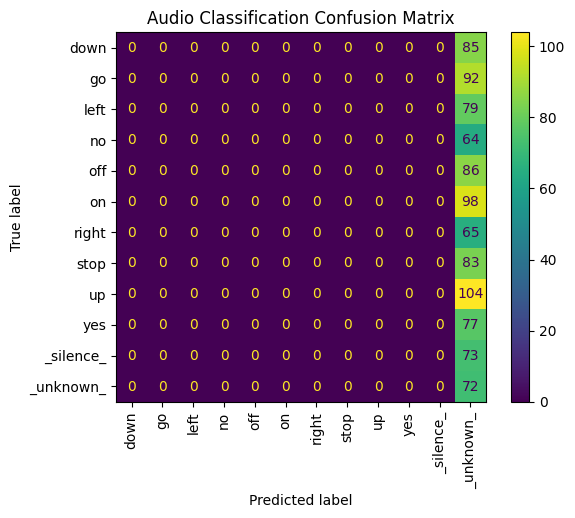

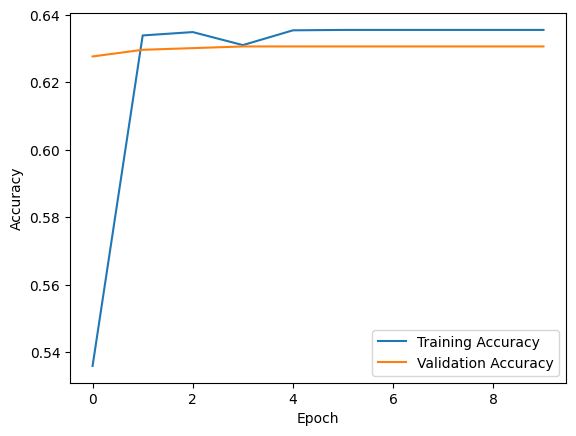

In [33]:
# Evaluate model using accuracy and confusion matrix

y_true = []
y_pred = []

for audio_batch, label_batch in test_ds:
    predictions = model.predict(audio_batch, verbose=0)

    y_true.extend(label_batch.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

accuracy = accuracy_score(y_true, y_pred)

print("Test Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(xticks_rotation=90)

plt.title("Audio Classification Confusion Matrix")
plt.show()

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [34]:

# Upload audio, convert speech to text, and classify audio

uploaded = files.upload()
audio_file = next(iter(uploaded))

recognizer = sr.Recognizer()
text = ""

# Speech-to-Text
try:
    with sr.AudioFile(audio_file) as source:
        recorded_audio = recognizer.record(source)

    text = recognizer.recognize_google(recorded_audio)
    print("Recognized Speech:", text)

except sr.UnknownValueError:
    print("Speech-to-Text: Could not understand the audio.")

except sr.RequestError as e:
    print("Speech-to-Text service error:", e)

except Exception as e:
    print("Speech-to-Text error:", e)


# CNN Audio Classification
try:
    audio_data = tf.io.read_file(audio_file)

    waveform, sample_rate = tf.audio.decode_wav(
        audio_data,
        desired_channels=1
    )

    waveform = tf.squeeze(waveform, axis=-1)
    waveform = tf.cast(waveform, tf.float32)

    # Convert audio to 16 kHz if required
    if int(sample_rate) != 16000:
        new_length = tf.cast(
            tf.round(
                tf.cast(tf.shape(waveform)[0], tf.float32)
                * 16000 / tf.cast(sample_rate, tf.float32)
            ),
            tf.int32
        )

        waveform = tf.image.resize(
            waveform[tf.newaxis, :, tf.newaxis],
            [new_length, 1],
            method="bilinear"
        )[0, :, 0]

    # Make audio exactly one second long
    waveform = waveform[:16000]

    waveform = tf.pad(
        waveform,
        [[0, tf.maximum(0, 16000 - tf.shape(waveform)[0])]]
    )

    # Generate spectrogram
    spectrogram = tf.abs(
        tf.signal.stft(
            waveform,
            frame_length=256,
            frame_step=128
        )
    )

    spectrogram = spectrogram[tf.newaxis, ..., tf.newaxis]

    # Predict the audio class
    prediction = model.predict(spectrogram, verbose=0)[0]

    predicted_class = class_names[np.argmax(prediction)]
    confidence = float(np.max(prediction)) * 100

    print("\nPredicted Audio Class:", predicted_class)
    print("Confidence:", f"{confidence:.2f}%")

except Exception as e:
    print("Audio classification error:", e)


Saving 2ad772d6_nohash_1.wav to 2ad772d6_nohash_1 (1).wav
Recognized Speech: stop

Predicted Audio Class: _unknown_
Confidence: 63.32%


In [35]:

# Display the top 5 predictions for the uploaded audio

top_indices = np.argsort(prediction)[-5:][::-1]

print("Top 5 predicted classes:")
for i in top_indices:
    print(f"{class_names[i]}: {prediction[i] * 100:.2f}%")


Top 5 predicted classes:
_unknown_: 63.32%
no: 3.84%
yes: 3.72%
stop: 3.67%
down: 3.59%


In [36]:


# Convert entered text into spoken audio

from gtts import gTTS
from IPython.display import Audio, display

text_input = input("Enter text to convert into speech: ")

if text_input.strip():
    try:
        tts = gTTS(text=text_input, lang="en")
        tts.save("generated_speech.mp3")

        print("Text converted into speech successfully!")
        display(Audio("generated_speech.mp3", autoplay=False))

    except Exception as e:
        print("Text-to-Speech error:", e)
else:
    print("Please enter some text.")


Enter text to convert into speech: RIGHT
Text converted into speech successfully!


In [37]:


# Save the trained audio classification model

model.save("audio_classification_cnn.keras")

print("CNN model saved successfully!")


CNN model saved successfully!
